In [1]:
import sys

sys.path.append("..")

import numpy as np
from scipy.linalg import svd
from scipy.integrate import odeint
from classes.loader.loader import Loader
from classes.feature.ssi import SSI
from classes.feature.utils import compute_poles
from classes.signal import SignalTime
import matplotlib.pyplot as plt
import scipy
from tqdm.notebook import tqdm

# Simulated data

In [2]:
def simulate(M, C, K, Ts, N):
    n = M.shape[0]

    # Assemble into state-space matrices
    A = np.block([[np.zeros((n,n)), np.eye(n)],
                [-np.linalg.inv(M) @ K, -np.linalg.inv(M) @ C]])

    B = np.block([np.zeros((n,n)), np.linalg.inv(M)]).T

    # Sampling time
    ts = 0.01

    # Compute discrete-time matrices
    Ad, Bd, _, _, _ = scipy.signal.cont2discrete((A,B,np.eye(2*n),np.zeros((2*n,n))), ts)

    # simulation
    x = np.zeros((6,1))
    u = np.random.randn(N)
    y = []
    for n in range(N):
        x_next = np.matmul(Ad, x) + np.matmul(Bd, np.array([u[n],0,0]).reshape(-1,1))
        y.append(x[[0,1]])
        x = x_next.copy()
    y_array = np.array(y).squeeze()
    signals_list = [SignalTime(y_array[:,k], ts, None) for k in range(y_array.shape[1])]
    poles = compute_poles(Ad, ts)
    return signals_list, poles

In [3]:
M = np.array([[1, 0, 0],
              [0, 1, 0],
              [0, 0, 1]])

# Damping matrix (C)
C = np.array([[0.1, 0, 0],
              [0, 0.1, 0],
              [0, 0, 0.1]])

# Stiffness matrix (K)
k = 100
K = np.array([[2*k, -1*k, 0],
              [-1*k, 2*k, -1*k],
              [0, -1*k, 1*k]])
Ts = 1 / 256
signals, poles_real = simulate(M, C, K, Ts, N=2**12)

In [4]:
ssi = SSI(max_order=6, sval_percent=0.99)
poles, meta = ssi.predict(signals)

In [5]:
# for ord, poles in enumerate(stab):
#     for pole in poles:
#         plt.scatter(pole.fn, ord)
# plt.xlim([0,10])

(0.0, 10.0)

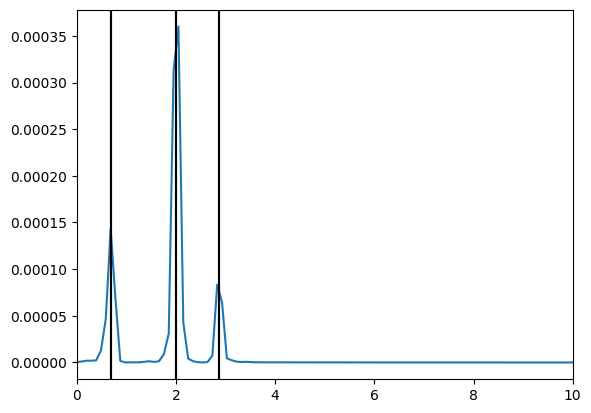

In [6]:
f, X = scipy.signal.welch(signals[0].get()[1], fs=1/signals[0].ts, nperseg=1024)
plt.plot(f,X)
for pole in poles:
    plt.axvline(pole.fn, color="k")
plt.xlim([0,10])

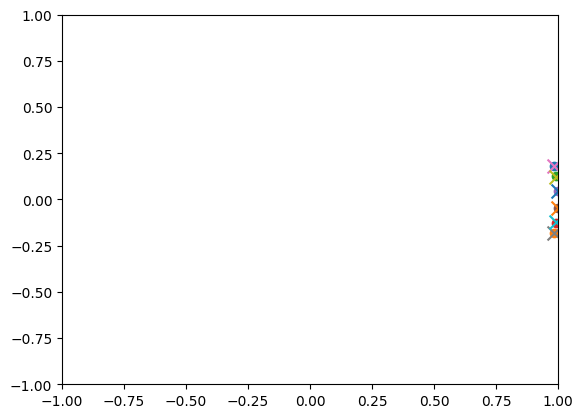

In [7]:
for pole in poles:
    plt.scatter(pole.z.real, pole.z.imag)

for pole in poles_real:
    plt.scatter(pole.z.real, pole.z.imag, marker="x", s=100)
    plt.xlim([-1,1])
    plt.ylim([-1,1])

# Real data

In [52]:
loader = Loader(r"..\raw\sequence_1")
sample = loader.load_one("2022_11_18_12_34.json")
single_sample = sample.sample_c1
single_sample.convert_to_time()
sx = single_sample.x
sy = single_sample.y
sz = single_sample.z

In [80]:
def bandpass(signal: SignalTime, f0: float, f1: float) -> SignalTime:
    fs = 1 / signal.ts
    butter_sos = scipy.signal.butter(5, Wn=[f0, f1], btype="bandpass", fs=fs, output="sos")
    _, x = signal.get()
    x_filt = scipy.signal.sosfilt(butter_sos, x)
    return SignalTime(list(x_filt), signal.ts, None)

In [81]:
f0 = 30
f1 = 50
signals = [bandpass(sz, f0, f1), bandpass(sy, f0, f1)]
signals = [signals[0]]
ssi = SSI(max_order=40, sval_percent=0.9)
poles, meta = ssi.predict(signals)

61.74513277462433 True
61.74513277462433 True
41.76256161311372 True
41.76256161311372 True
43.23261740593972 True
43.23261740593972 True
47.90258356134146 True
47.90258356134146 True


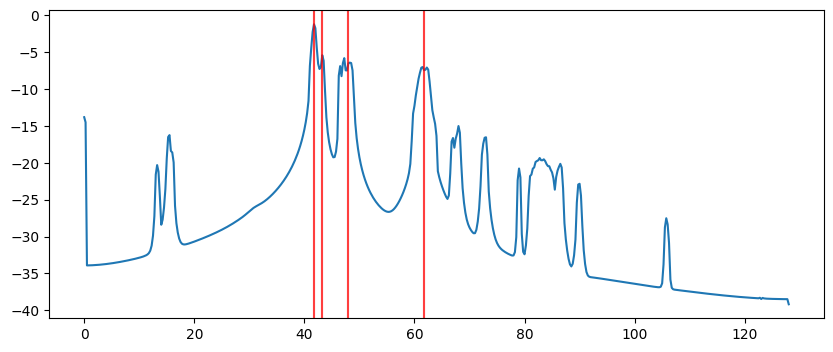

In [82]:
f, X1 = scipy.signal.welch(signals[0].get()[1], fs=1/signals[0].ts, nperseg=1024)
# f, X2 = scipy.signal.welch(signals[1].get()[1], fs=1/signals[0].ts, nperseg=1024)

fig = plt.figure(figsize=(10,4))
ax = fig.add_subplot()

ax.plot(f, np.log(X1))
# ax.plot(f, np.log(X2))
for pole in poles:
    is_unstable = np.abs(pole.z) > 1
    color = "k" if not is_unstable else "red"
    ax.axvline(pole.fn, color=color, alpha=0.5)
    print(pole.fn, is_unstable)

# ax2 = ax.twinx()
# for pole in poles:
#     ax2.plot([pole.fn]*2, [0, np.abs(pole.a[0])], color="red", marker="o")
# plt.xlim([0,10])